# Lab 2. Operacje morfologiczne

Operacje morfologiczne to metody przetwarzania obrazów służące do analizy i modyfikacji kształtu oraz struktury obiektów.
Ich działanie opiera się na wykorzystaniu elementu strukturalnego (kernela), który określa lokalne sąsiedztwo analizowanych pikseli.

Podstawowe operacje morfologiczne:
- Erozja – zmniejsza obszary obiektów.
- Dylatacja – powiększa obszary obiektów.
- Otwarcie – usuwa drobne obiekty i wypustki.
- Zamknięcie – wypełnia niewielkie przerwy i szczeliny.
- Hit-or-Miss – wykrywa określone wzorce pikseli.

Zastosowanie:
usuwanie szumu, poprawa segmentacji, analiza kształtów, wykrywanie struktur oraz przygotowanie obrazów do dalszej analizy.

Operacje te stosuje się przede wszystkim do obrazów binarnych, ale wiele z nich można również wykonywać na obrazach w skali szarości.

# Wymagane biblioteki

In [4]:
import numpy as np  # Obsługa tablic i operacji matematycznych
import matplotlib.pyplot as plt  # Wyświetlanie obrazów i wykresów

# Funkcje morfologiczne z biblioteki skimage
from skimage.morphology import (binary_dilation, binary_erosion,
                                 binary_opening, binary_closing,
                                 skeletonize, convex_hull_image,
                                 thin)

from skimage.segmentation import find_boundaries  # Detekcja granic obiektów
from skimage.util import invert  # Negacja (odwrócenie) obrazu binarnego
from skimage.data import binary_blobs  # Generowanie przykładowych obrazów binarnych
from scipy.ndimage import distance_transform_edt  # Transformata odległościowa (Euclidean Distance Transform)



# 1. Obraz binarny testowy

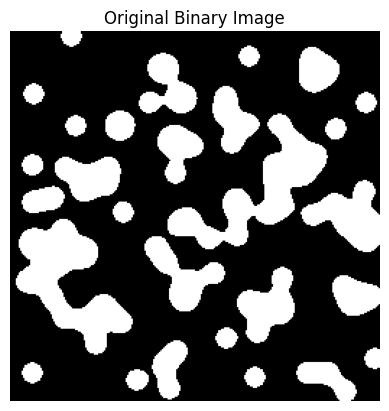

In [5]:
#Wygeneruj syntetyczny obraz binarny o losowych kształtach
image = binary_blobs(length=256, blob_size_fraction=0.1, n_dim=2, volume_fraction=0.3)

# Wyświetl obraz
plt.imshow(image, cmap='gray')
plt.title("Original Binary Image")
plt.axis('off')
plt.show()

# 2. Dylacja i Erozja

C:\Users\user\AppData\Local\Temp\ipykernel_23728\1367590162.py:2: FutureWarning: `binary_dilation` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.dilation` instead. Note the lack of mirroring for non-symmetric footprints (see docstring notes).
  dilated = binary_dilation(image)
C:\Users\user\AppData\Local\Temp\ipykernel_23728\1367590162.py:5: FutureWarning: `binary_erosion` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.erosion` instead. Note the pixel shift by 1 for even-sized footprints (see docstring notes).
  eroded = binary_erosion(image)


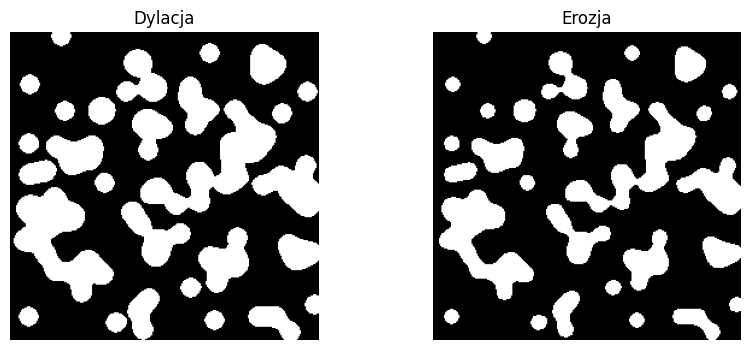

In [6]:
# Zastosuj dylację – rozszerzenie obiektów
dilated = binary_dilation(image)

# Zastosuj erozję – skurczenie obiektów
eroded = binary_erosion(image)

# Wyświetl efekty obok siebie
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(dilated, cmap='gray')
axes[0].set_title("Dylacja")  # Rozrost obiektów
axes[1].imshow(eroded, cmap='gray')
axes[1].set_title("Erozja")  # Skurczenie obiektów
for ax in axes:
    ax.axis('off')
plt.show()

# 3. Otwarcie i Zamknięcie

C:\Users\user\AppData\Local\Temp\ipykernel_23728\2120852498.py:2: FutureWarning: `binary_opening` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.opening` instead.
  opened = binary_opening(image)
C:\Users\user\AppData\Local\Temp\ipykernel_23728\2120852498.py:5: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  closed = binary_closing(image)


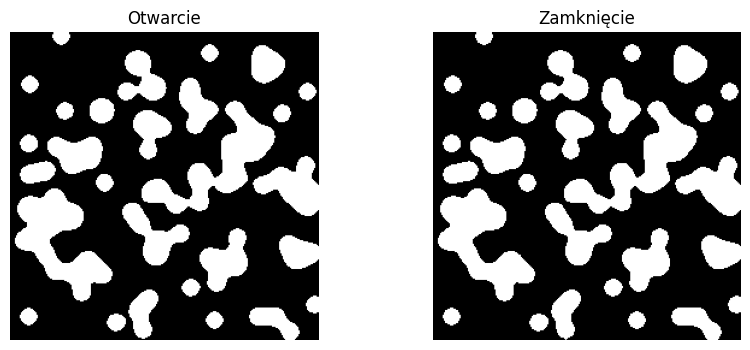

In [7]:
# Otwarcie: erozja + dylacja — usuwa drobne obiekty
opened = binary_opening(image)

# Zamknięcie: dylacja + erozja — wypełnia małe dziury
closed = binary_closing(image)

# Wyświetl wyniki
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(opened, cmap='gray')
axes[0].set_title("Otwarcie")
axes[1].imshow(closed, cmap='gray')
axes[1].set_title("Zamknięcie")
for ax in axes:
    ax.axis('off')
plt.show()

# 4. Granice obiektu

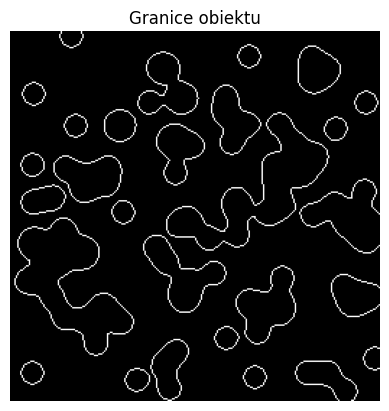

In [8]:
# Wyodrębnij zewnętrzne granice obiektów
boundaries = find_boundaries(image, mode='outer')

# Wyświetl granice
plt.imshow(boundaries, cmap='gray')
plt.title("Granice obiektu")
plt.axis('off')
plt.show()

# 5. Szkielet (Skeletonization)

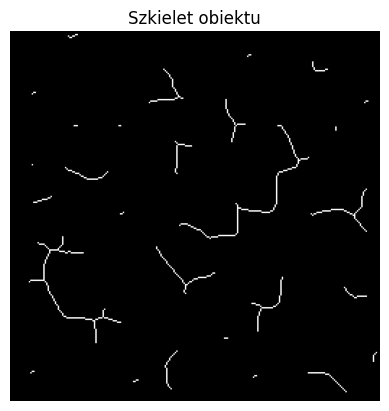

In [9]:
# Wygeneruj szkielet binarny obiektu (linia przechodząca przez środek)
skeleton = skeletonize(image)

# Wyświetl szkielet
plt.imshow(skeleton, cmap='gray')
plt.title("Szkielet obiektu")
plt.axis('off')
plt.show()

# 6. Ścienianie (Thinning)

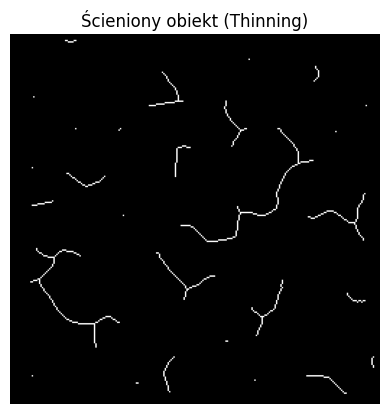

In [10]:
# Zastosuj operację ścieniania — zmniejsza grubość obiektów do jednej linii
thinned = thin(image)

# Wyświetl wynik
plt.imshow(thinned, cmap='gray')
plt.title("Ścieniony obiekt (Thinning)")
plt.axis('off')
plt.show()

# 7. Operacja Hit-or-Miss – wykrywanie wzorców

Hit-or-Miss to operacja morfologiczna stosowana do wykrywania określonych wzorców i struktur w obrazach binarnych.
Operacja wykorzystuje dwa elementy strukturalne:
- Pierwszy określa układ pikseli obiektu (wartość 1).
- Drugi określa wymagany układ pikseli tła (wartość 0).

Operacja **Hit-or-Miss** wykorzystuje dwa elementy strukturalne:

- **Pierwszy ($B_1$)** określa układ pikseli obiektu (wartość 1).
- **Drugi ($B_2$)** określa wymagany układ pikseli tła (wartość 0).

Piksel zostaje zaznaczony w obrazie wynikowym tylko wtedy, gdy oba warunki są jednocześnie spełnione.

**Zapis matematyczny:**

$$
A \circledast (B_1,B_2) = (A \ominus B_1) \cap (A^c \ominus B_2)
$$

gdzie:

- $A$ – obraz binarny,
- $A^c$ – dopełnienie obrazu,
- $B_1, B_2$ – elementy strukturalne,
- $\ominus$ – erozja.

Zastosowania:
- wykrywanie narożników i zakończeń linii,
- identyfikacja charakterystycznych układów pikseli,
- analiza szkieletów obiektów,
- wykrywanie określonych struktur geometrycznych.

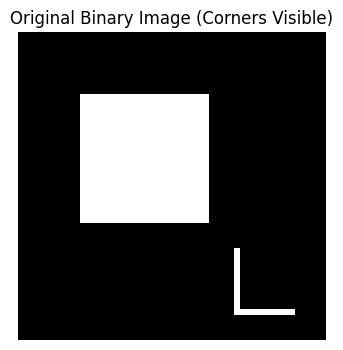

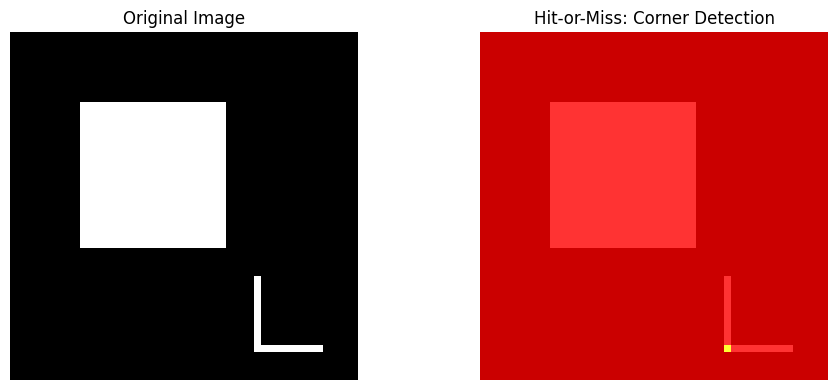

In [11]:
# ===============================================
# Import wymaganych bibliotek
# ===============================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import binary_hit_or_miss
from skimage.draw import rectangle

# ===============================================
# 1. Tworzymy obraz testowy z wyraźnymi narożnikami
# ===============================================

# Pusty obraz binarny
image = np.zeros((50, 50), dtype=bool)

# Dodajemy kwadrat – wyraźne cztery rogi
rr, cc = rectangle(start=(10, 10), end=(30, 30))
image[rr, cc] = True

# Dodajemy literę "L" w prawym dolnym rogu
image[35:45, 35] = True  # pionowa kreska
image[45, 35:45] = True  # pozioma kreska

# Wyświetlamy oryginalny obraz
plt.figure(figsize=(4, 4))
plt.imshow(image, cmap='gray')
plt.title("Original Binary Image (Corners Visible)")
plt.axis('off')
plt.show()

# ===============================================
# 2. Definiujemy wzorce (elementy strukturalne)
# ===============================================

# Operacja Hit-or-Miss wykrywa określony układ pikseli.
# Poniżej definiujemy wzorce dla 4 typów rogów ("L" w różnych orientacjach).

# Narożnik górny-lewy
se_tl_1 = np.array([[0, 0, 0],
                    [0, 1, 1],
                    [0, 1, 0]])
se_tl_2 = np.array([[1, 1, 1],
                    [1, 0, 0],
                    [1, 0, 1]])

# Narożnik górny-prawy
se_tr_1 = np.rot90(se_tl_1, 1)
se_tr_2 = np.rot90(se_tl_2, 1)

# Narożnik dolny-prawy
se_br_1 = np.rot90(se_tl_1, 2)
se_br_2 = np.rot90(se_tl_2, 2)

# Narożnik dolny-lewy
se_bl_1 = np.rot90(se_tl_1, 3)
se_bl_2 = np.rot90(se_tl_2, 3)

# ===============================================
# 3. Wykonujemy operacje Hit-or-Miss dla każdego wzorca
# ===============================================

hit_tl = binary_hit_or_miss(image, structure1=se_tl_1, structure2=se_tl_2)
hit_tr = binary_hit_or_miss(image, structure1=se_tr_1, structure2=se_tr_2)
hit_br = binary_hit_or_miss(image, structure1=se_br_1, structure2=se_br_2)
hit_bl = binary_hit_or_miss(image, structure1=se_bl_1, structure2=se_bl_2)

# Sumujemy wszystkie wyniki, aby uzyskać pełną mapę narożników
corners = hit_tl | hit_tr | hit_br | hit_bl

# ===============================================
# 4. Wizualizacja wyników
# ===============================================

fig, axs = plt.subplots(1, 2, figsize=(10, 4))

# Obraz oryginalny
axs[0].imshow(image, cmap='gray')
axs[0].set_title("Original Image")
axs[0].axis('off')

# Obraz z wykrytymi narożnikami (nałożone czerwone punkty)
axs[1].imshow(image, cmap='gray')
axs[1].imshow(corners, cmap='autumn', alpha=0.8)
axs[1].set_title("Hit-or-Miss: Corner Detection")
axs[1].axis('off')

plt.tight_layout()
plt.show()

## Dlaczego widzisz żółty punkt tylko w jednym miejscu (na literze “L”), mimo że kwadrat też ma przecież rogi?

Żółty punkt pojawia się tylko na literze „L”, ponieważ operacja Hit-or-Miss wykrywa konkretny układ pikseli zdefiniowany przez element strukturalny, a nie wszystkie narożniki obrazu.
W tym przypadku element strukturalny odpowiada narożnikowi litery „L”, gdzie dwa ramiona obiektu są otoczone odpowiednio rozmieszczonymi pikselami tła.
Kwadrat również ma narożniki, ale ich lokalne otoczenie pikselowe jest inne – wnętrze kwadratu jest wypełnione, dlatego nie spełnia warunków dopasowania wzorca.
Wniosek: Hit-or-Miss nie jest uniwersalnym detektorem narożników. Wykrywa wyłącznie te struktury, które dokładnie odpowiadają zadanemu wzorcowi. Aby wykrywać inne typy narożników, należy zastosować odpowiednie elementy strukturalne, np. ich obrócone warianty.

# Hit and miss: Poprawiony kod – działa na wszystkich rogach

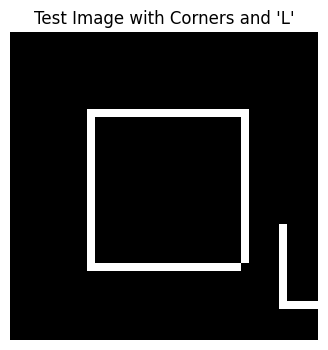

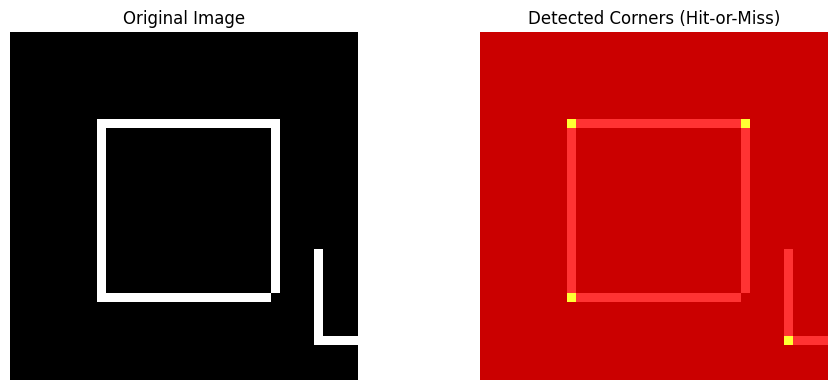

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import binary_hit_or_miss

# ===============================================
# 1. Tworzymy obraz z ramką (pusty kwadrat)
# ===============================================

image = np.zeros((40, 40), dtype=bool)

# Ramka kwadratu
image[10, 10:30] = True   # górna krawędź
image[30, 10:30] = True   # dolna krawędź
image[10:30, 10] = True   # lewa krawędź
image[10:30, 30] = True   # prawa krawędź

# Dodajemy literę "L" w prawym dolnym rogu dla porównania
image[25:35, 35] = True   # pionowa kreska
image[35, 35:45] = True   # pozioma kreska

plt.figure(figsize=(4, 4))
plt.imshow(image, cmap='gray')
plt.title("Test Image with Corners and 'L'")
plt.axis('off')
plt.show()

# ===============================================
# 2. Definicje wzorców narożników "L"
# ===============================================

# Narożnik górny-lewy
se_tl_1 = np.array([[0, 0, 0],
                    [0, 1, 1],
                    [0, 1, 0]])
se_tl_2 = np.array([[1, 1, 1],
                    [1, 0, 0],
                    [1, 0, 1]])

# Obracamy wzorce w 4 kierunki
se_tr_1 = np.rot90(se_tl_1, 1); se_tr_2 = np.rot90(se_tl_2, 1)
se_br_1 = np.rot90(se_tl_1, 2); se_br_2 = np.rot90(se_tl_2, 2)
se_bl_1 = np.rot90(se_tl_1, 3); se_bl_2 = np.rot90(se_tl_2, 3)

# ===============================================
# 3. Wykrywanie rogów w 4 kierunkach
# ===============================================

hit_tl = binary_hit_or_miss(image, structure1=se_tl_1, structure2=se_tl_2)
hit_tr = binary_hit_or_miss(image, structure1=se_tr_1, structure2=se_tr_2)
hit_br = binary_hit_or_miss(image, structure1=se_br_1, structure2=se_br_2)
hit_bl = binary_hit_or_miss(image, structure1=se_bl_1, structure2=se_bl_2)

# Sumujemy wyniki z różnych kierunków
corners = hit_tl | hit_tr | hit_br | hit_bl

# ===============================================
# 4. Wizualizacja wyników
# ===============================================

fig, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].imshow(image, cmap='gray')
axs[0].set_title("Original Image")
axs[0].axis('off')

axs[1].imshow(image, cmap='gray')
axs[1].imshow(corners, cmap='autumn', alpha=0.8)
axs[1].set_title("Detected Corners (Hit-or-Miss)")
axs[1].axis('off')

plt.tight_layout()
plt.show()

# 9. Wypukła otoczka (Convex Hull)

Wypukła otoczka to najmniejszy zbiór wypukły zawierający wszystkie piksele danego obiektu.
Operacja polega na wyznaczeniu zewnętrznej granicy obiektu w taki sposób, aby połączyć jego najbardziej wysunięte punkty i wyeliminować wklęsłości.

Najważniejsze właściwości:
- Wypełnia wklęsłości w konturze obiektu.
- Zachowuje najbardziej wysunięte punkty obiektu.
- Nie zmniejsza powierzchni oryginalnego obiektu.
- Może być wyznaczana osobno dla każdego obiektu w obrazie binarnym.

Zastosowania:
- analiza kształtu obiektów,
- wykrywanie wklęsłości i nieregularności konturów,
- obliczanie miar geometrycznych, np. solidity,
- analiza i porównywanie kształtów.

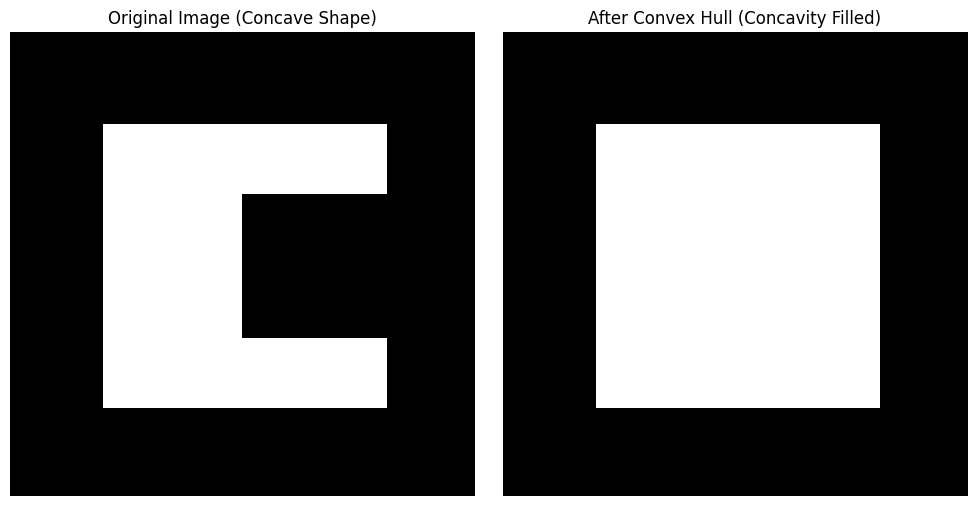

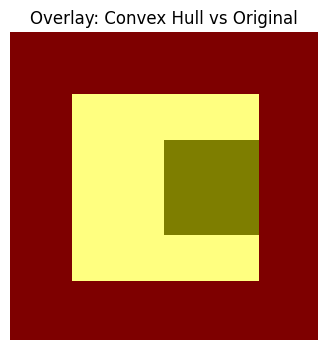

In [13]:
# Import wymaganych bibliotek
import numpy as np                      # Do pracy na tablicach numerycznych
import matplotlib.pyplot as plt          # Do wizualizacji wyników
from skimage.morphology import convex_hull_image  # Funkcja do obliczania wypukłej otoczki
from skimage.draw import rectangle       # Pomoc do rysowania prostokątów

# ===============================================
# 1. Tworzymy obraz testowy – obiekt z wklęsłością
# ===============================================

# Tworzymy pusty obraz 100x100 pikseli (czarne tło)
image = np.zeros((100, 100), dtype=bool)

# Dodajemy duży biały prostokąt – główne ciało obiektu
rr, cc = rectangle(start=(20, 20), end=(80, 80))
image[rr, cc] = True

# Wycinamy fragment środka, żeby powstała "wklęsłość" – np. litera "C"
rr_hole, cc_hole = rectangle(start=(35, 50), end=(65, 80))
image[rr_hole, cc_hole] = False

# ===============================================
# 2. Obliczamy wypukłą otoczkę (Convex Hull)
# ===============================================

# Funkcja convex_hull_image() zwraca najmniejszy wypukły kształt,
# który całkowicie obejmuje obiekt wejściowy.
convex_hull = convex_hull_image(image)

# ===============================================
# 3. Wizualizacja wyniku
# ===============================================

# Tworzymy dwa obrazy obok siebie: oryginał i jego otoczkę
fig, axs = plt.subplots(1, 2, figsize=(10, 5))

# (a) Obraz oryginalny
axs[0].imshow(image, cmap='gray')
axs[0].set_title("Original Image (Concave Shape)")  # Widać „wklęsłość”
axs[0].axis('off')

# (b) Obraz po zastosowaniu Convex Hull
axs[1].imshow(convex_hull, cmap='gray')
axs[1].set_title("After Convex Hull (Concavity Filled)")  # Wklęsłość została wypełniona
axs[1].axis('off')

plt.tight_layout()
plt.show()

# ===============================================
# 4. Analiza wyniku
# ===============================================

# Dla lepszej wizualizacji różnic — nałóżmy wynik otoczki na oryginał
plt.figure(figsize=(4, 4))
plt.imshow(image, cmap='gray')               # oryginał jako tło
plt.imshow(convex_hull, cmap='autumn', alpha=0.5)  # otoczka w półprzezroczystym kolorze
plt.title("Overlay: Convex Hull vs Original")
plt.axis('off')
plt.show()

## Zadanie 1. Analiza mikroskopowego obrazu komórek / ziaren pyłku

Celem zadania jest przećwiczenie podstawowych operacji morfologicznych na realistycznym obrazie mikroskopowym komórek, w tym:

* poprawy kontrastu,
* ręcznego progowania,
* filtracji szumów i wypełniania obiektów,
* wyodrębnienia granic komórek.

Student powinien zrozumieć, jak kolejne kroki przetwarzania obrazu wpływają na jakość segmentacji.

Opis zadania

Używając biblioteki scikit-image, wykonaj kompletny proces segmentacji komórek z przykładowego obrazu mikroskopowego data.cells3d().


---



## Etapy, które należy zrealizować:

# 1. Wczytanie obrazu mikroskopowego:

* **Użyj danych wbudowanych w skimage.data.cells3d().**
* **Wybierz jeden kanał (np. jądrowy) i jedną warstwę obrazu 3D.**

Funkcja skimage.data.cells3d() zwraca trójwymiarowy obraz mikroskopowy komórek (3D image stack), pochodzący z mikroskopii konfokalnej.
Dane te są dostępne w bibliotece scikit-image jako przykładowy zestaw danych biologicznych.

Obraz ma cztery wymiary: shape = (Z, Channels, Y, X)

czyli:

Z – liczba warstw (głębokość, kolejne przekroje 3D),
Channels – różne kanały barwne / fluorescencyjne (np. DNA, błony komórkowe),
Y – wysokość obrazu (liczba wierszy),
X – szerokość obrazu (liczba kolumn).

Co robi linijka: image_gray = data.cells3d()[:, 1, :, :]
Znaczenie poszczególnych indeksów:

* : → pobiera wszystkie warstwy (Z)
* 1 → wybiera kanał nr 1 (drugi kanał, tzw. nuclear channel)
* :, : → pobiera wszystkie piksele w wymiarach Y i X

Efekt:

Otrzymujemy trójwymiarowy obraz (Z × Y × X) pokazujący rozkład fluorescencji jądrowej komórek.

Dlaczego kanał 1?

- Kanał 0 w cells3d() odpowiada barwieniu błon komórkowych,
- Kanał 1 – barwieniu jąder komórkowych (DNA),
czyli tego, co najczęściej analizujemy w segmentacji biologicznej.

image_gray = image_gray[30]
Ten krok wybiera jedną warstwę (Z-slice) z trójwymiarowego stosu obrazów. Wartość 30 to po prostu numer przekroju (można użyć innego, np. 10, 20, 40...). Wynikiem jest obraz 2D, który można łatwo wyświetlić i analizować za pomocą morfologii.

* **Wyświetl obraz w skali szarości.**

# 2. Poprawa Kontrastu

Użyj funkcji exposure.equalize_hist() w celu wyrównania histogramu jasności.

* Porównaj obraz przed i po poprawie kontrastu.
* Wyjaśnij, dlaczego ten krok ułatwia dalsze progowanie.

# 3. Ręczne progowanie

* Dobierz ręcznie wartość progu (threshold_value), np. 0.3–0.5.
* Zastosuj maskę binarną, gdzie True odpowiada obiektom (komórkom).
* Zbadaj, jak zmiana progu wpływa na liczbę i kształt wykrytych komórek.

# 4.Otwarcie morfologiczne (Opening)

* Użyj morphology.binary_opening() z elementem strukturalnym disk(2).
* Usuń drobny szum i małe artefakty z binarnego obrazu.
* Zobrazuj efekt tej operacji.

# 5.Zamknięcie morfologiczne (Closing)

* Zastosuj morphology.binary_closing() z elementem disk(3).
* Wypełnij małe dziury wewnątrz komórek i wygładź ich krawędzie.
* Porównaj wynik z obrazem po otwarciu.

# 6.Wyodrębnienie granic komórek

* Użyj segmentation.find_boundaries() do detekcji krawędzi obiektów.
* Nałóż kontury komórek na obraz w skali szarości, aby zwizualizować efekt segmentacji.
* Wizualizacja etapów przetwarzania
* Utwórz zestawienie wszystkich etapów w postaci siatki obrazów (2×3).
* Dodaj tytuły dla każdego etapu, np.:

In [14]:
%pip install pooch

Note: you may need to restart the kernel to use updated packages.


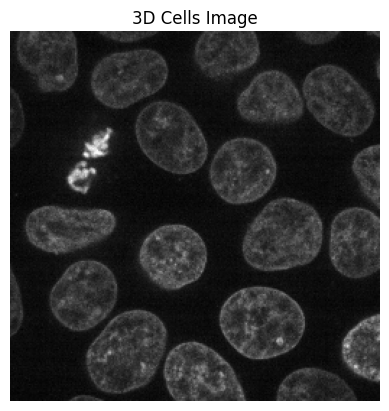

In [15]:
from skimage import data

image = data.cells3d()[:,1,:,:]
image = image[30]

plt.imshow(image, cmap='gray')
plt.title("3D Cells Image")
plt.axis('off')
plt.show()

In [30]:
def display_image(images, titles=None, cmap='gray'):
    """
    Wyświetla maksymalnie trzy obrazy w każdym wierszu.
    
    Parametry:
    images : list
        Lista obrazów do wyświetlenia.
    titles : list, opcjonalnie
        Lista tytułów dla każdego obrazu. Jeśli None, nie wyświetla tytułów.
    cmap : str, opcjonalnie
        Kolor mapy do użycia przy wyświetlaniu obrazów (domyślnie 'gray').
    """
    n = len(images)
    if n == 0:
        return

    columns = min(3, n)
    rows = (n + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(5 * columns, 5 * rows), squeeze=False)

    for i, image in enumerate(images):
        ax = axes[i // columns, i % columns]
        ax.imshow(image, cmap=cmap)
        if titles is not None:
            ax.set_title(titles[i])
        ax.axis('off')

    for i in range(n, rows * columns):
        axes[i // columns, i % columns].axis('off')

    plt.tight_layout()
    plt.show()

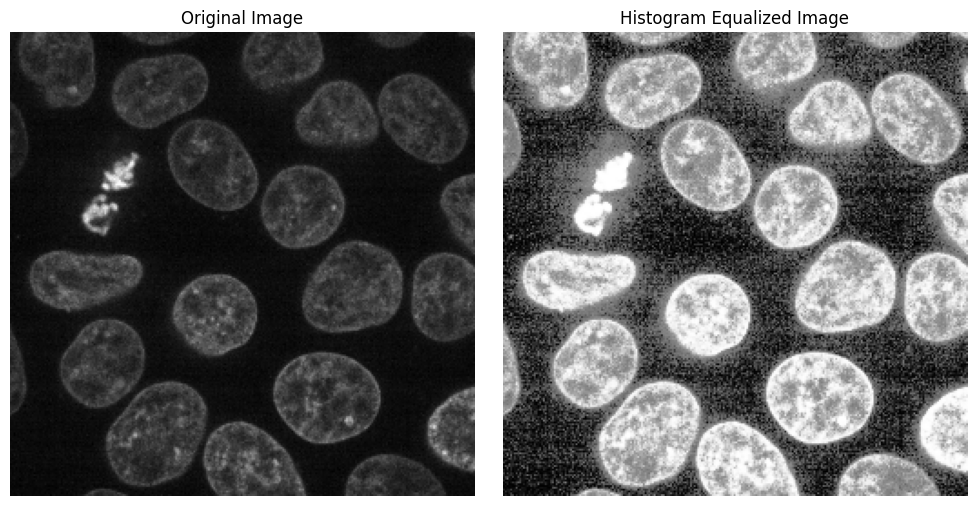

In [31]:
from skimage.exposure import equalize_hist

image_eq = equalize_hist(image,)

display_image([image, image_eq], titles=["Original Image", "Histogram Equalized Image"])

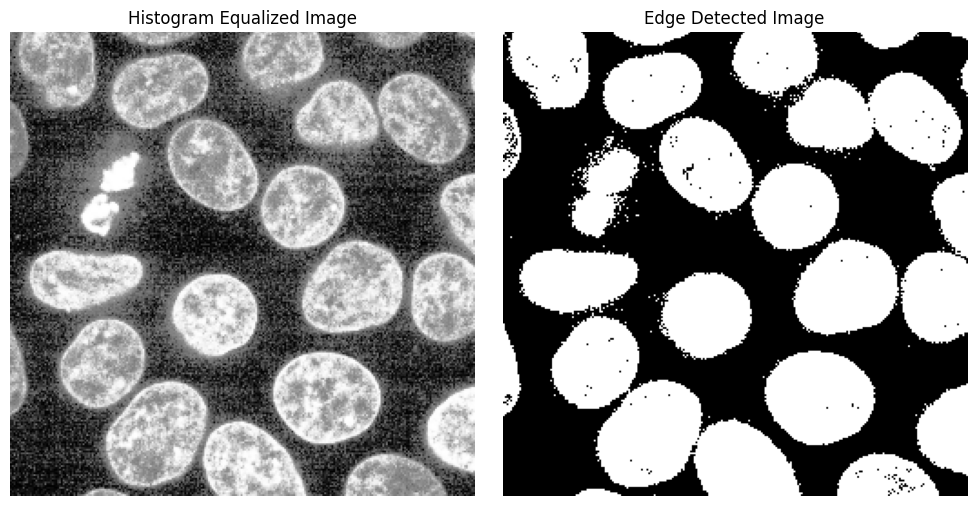

In [32]:
treshold_value = 0.5
edge_image = image_eq > treshold_value

display_image([image_eq, edge_image], titles=["Histogram Equalized Image", "Edge Detected Image"])

C:\Users\user\AppData\Local\Temp\ipykernel_23728\304406099.py:1: FutureWarning: `binary_erosion` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.erosion` instead. Note the pixel shift by 1 for even-sized footprints (see docstring notes).
  erased_image = binary_erosion(edge_image)


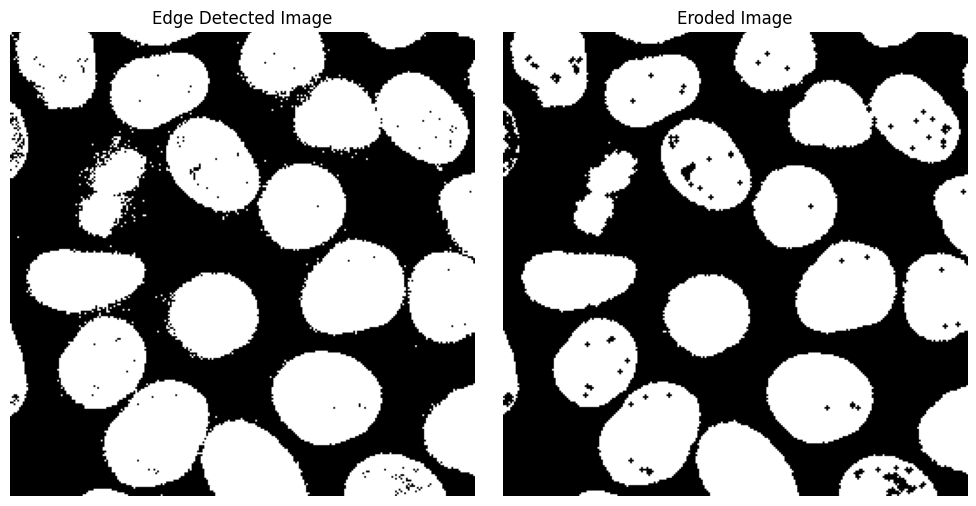

In [33]:
erased_image = binary_erosion(edge_image)

display_image([edge_image, erased_image], titles=["Edge Detected Image", "Eroded Image"])

C:\Users\user\AppData\Local\Temp\ipykernel_23728\1441993111.py:4: FutureWarning: `binary_opening` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.opening` instead.
  opened_image = binary_opening(erased_image, footprint=disk(2))
C:\Users\user\AppData\Local\Temp\ipykernel_23728\1441993111.py:5: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  closing_image = binary_closing(erased_image, footprint=disk(3))


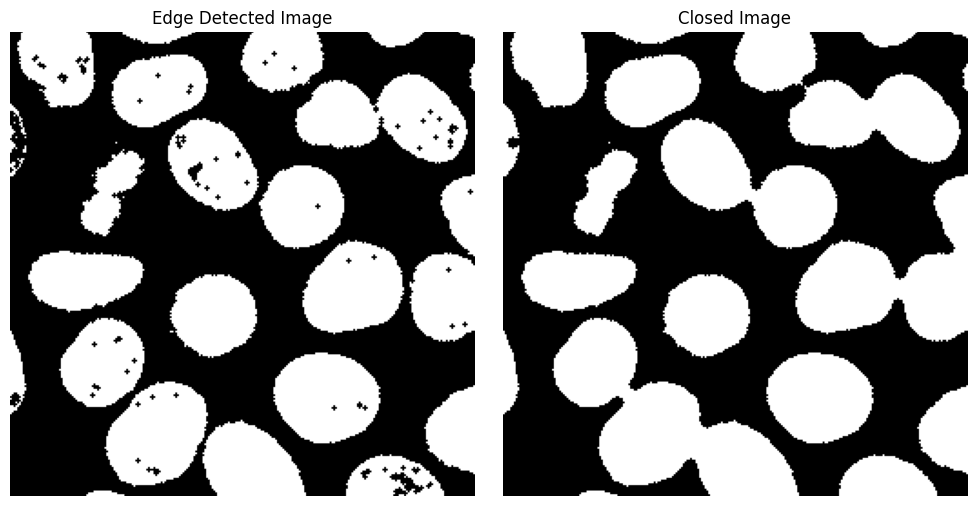

In [34]:
from skimage.morphology import disk
#findCountours

opened_image = binary_opening(erased_image, footprint=disk(2))
closing_image = binary_closing(erased_image, footprint=disk(3))

display_image([erased_image, closing_image], titles=["Edge Detected Image", "Closed Image"])

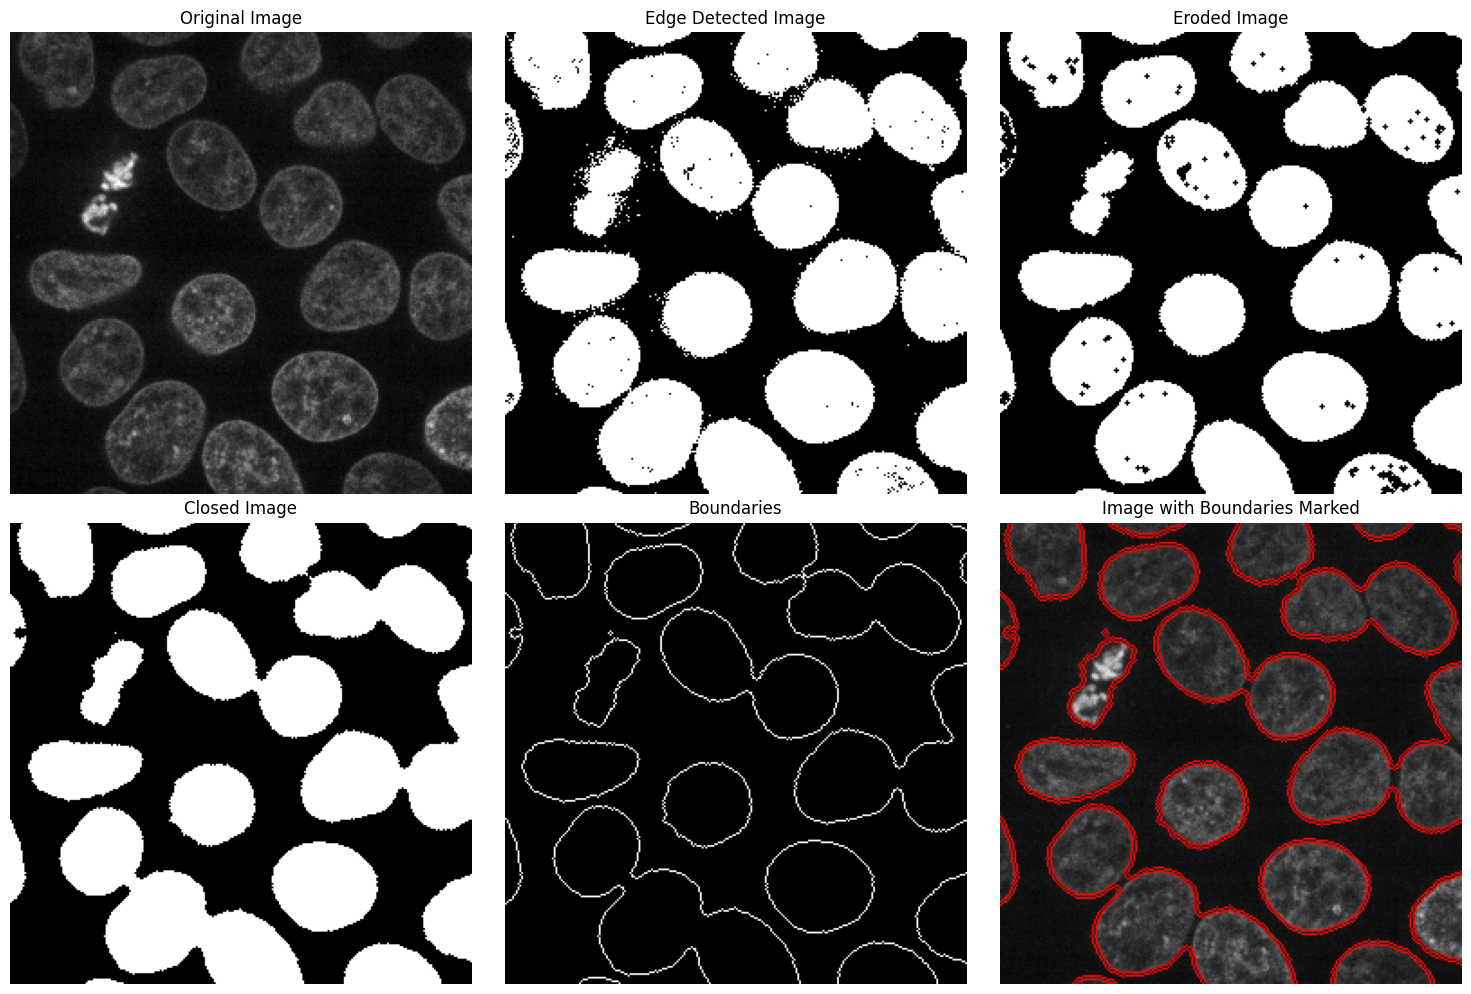

In [35]:
from skimage.segmentation import find_boundaries, mark_boundaries

boundaries = find_boundaries(closing_image, mode='outer')

result_image = mark_boundaries(image, boundaries, color=(1, 0, 0)) 
display_image([image, edge_image, erased_image, closing_image, boundaries, result_image], titles=["Original Image", "Edge Detected Image", "Eroded Image", "Closed Image", "Boundaries", "Image with Boundaries Marked"])

## Zadanie 2. Analiza kształtu obiektów z użyciem wypukłej otoczki (Convex Hull)
Celem zadania jest zrozumienie działania operacji wypukłej otoczki (Convex Hull) i jej wykorzystania do:

* opisu kształtu obiektów,
* wykrywania wklęsłości,
* porównania rzeczywistego kształtu z jego wypukłym przybliżeniem.

Student nauczy się, jak zastosować Convex Hull do prostych analiz geometrycznych na obrazach binarnych.


---



Opis problemu

Dany jest obraz przedstawiający obiekty o nieregularnych kształtach (np. komórki, ziarna piasku lub krople cieczy).
Celem jest:

* Oczyszczenie obrazu,
* Zastosowanie operacji Convex Hull dla każdego obiektu,
* Porównanie oryginalnych kształtów z ich otoczkami,
* Obliczenie miary „wklęsłości” obiektu, czyli różnicy między jego polem a polem jego wypukłej otoczki.


---



# Etapy projektu
**1. Wczytanie obrazu**

* Użyj wbudowanego obrazu skimage.data.coins() lub własnego binarnego zdjęcia z wyraźnymi obiektami (np. nasionami, liśćmi, pęcherzykami).
* Jeśli obraz jest w skali szarości – przekształć go w binarny przez progowanie.

**2.Czyszczenie obrazu**

* Usuń drobne zakłócenia za pomocą otwarcia i zamknięcia morfologicznego.

**3.Wykorzystanie Convex Hull**

* Dla każdego obiektu (etykiety) oblicz jego wypukłą otoczkę.
* Porównaj oryginalny kształt i jego wypukłe przybliżenie.

**4.Obliczenie miary wklęsłości**

* Dla każdego obiektu oblicz:
* pole oryginalnego obiektu,
* pole jego wypukłej otoczki,
* stosunek Concavity = (A_hull - A_object) / A_hull.

**5.Wizualizacja różnic (różnica pomiędzy obiektem a otoczką)**

* Wyświetl piksele, które należą do otoczki, ale nie do oryginalnego obiektu (czyli „wklęsłe fragmenty”).

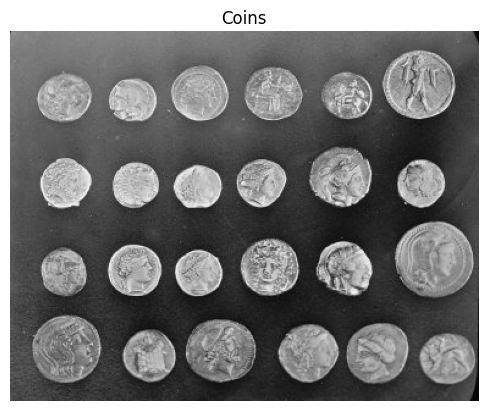

In [36]:
from skimage import data

coins = data.coins()

plt.imshow(coins, cmap='gray')
plt.title("Coins")
plt.axis('off')
plt.show()

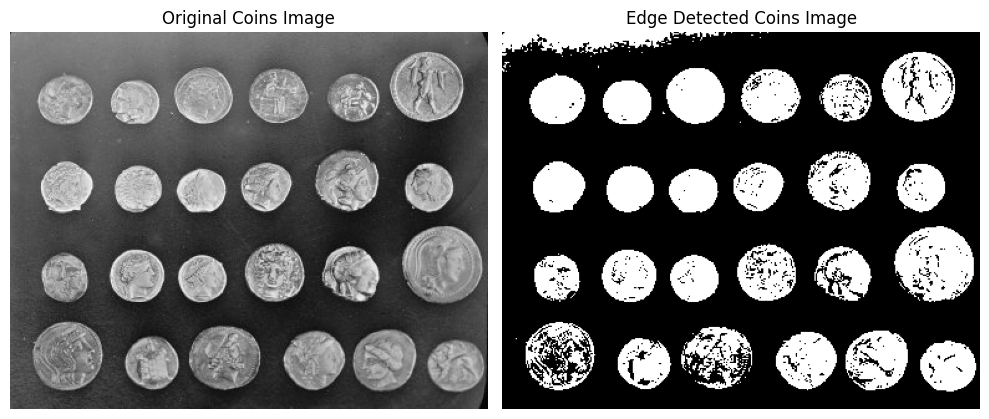

In [37]:
threshold_value = 125
edge_coins = coins > threshold_value

display_image([coins, edge_coins], titles=["Original Coins Image", "Edge Detected Coins Image"])

C:\Users\user\AppData\Local\Temp\ipykernel_23728\82474653.py:1: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  closing_coins = binary_closing(edge_coins, footprint=disk(3))
C:\Users\user\AppData\Local\Temp\ipykernel_23728\82474653.py:2: FutureWarning: `binary_erosion` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.erosion` instead. Note the pixel shift by 1 for even-sized footprints (see docstring notes).
  eroded_coins = binary_erosion(closing_coins)
C:\Users\user\AppData\Local\Temp\ipykernel_23728\82474653.py:3: FutureWarning: `binary_dilation` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.dilation` instead. Note the lack of mirroring for non-symmetric footprints (see docstring notes).
  dilated_coins = binary_dilation(eroded_coins)


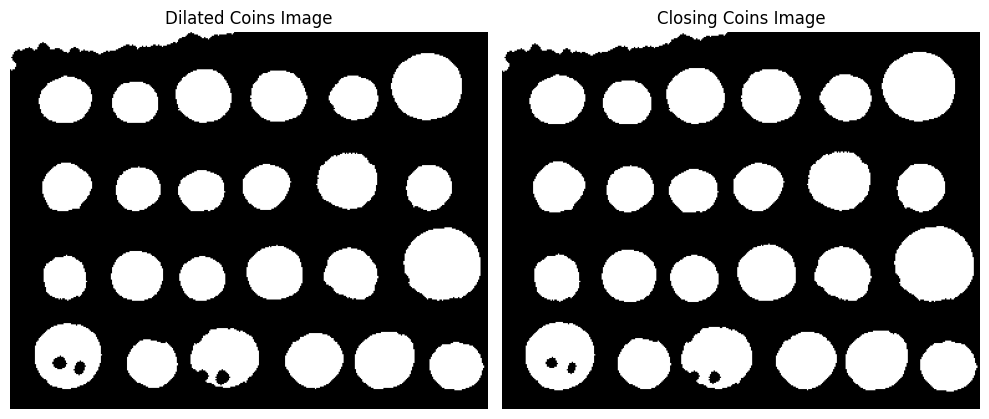

In [ ]:
closing_coins = binary_closing(edge_coins, footprint=disk(3))
eroded_coins = binary_erosion(closing_coins)
#dilated_coins = binary_dilation(eroded_coins)

display_image([eroded_coins, dilated_coins], titles=["Dilated Coins Image","Closing Coins Image"])

In [39]:
#%pip install opencv-python

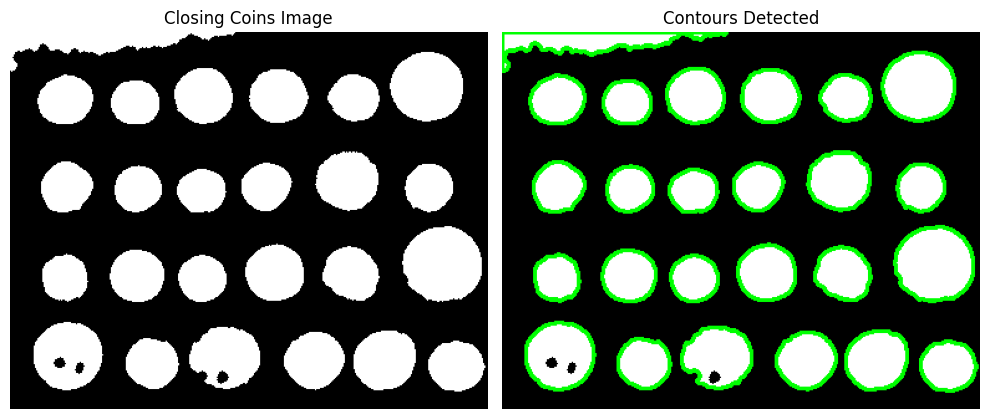

In [40]:
import cv2
closing_coins = dilated_coins

#sprawdzamy czy maska zgadza sie z ta do cv2
if closing_coins.dtype == bool or closing_coins.max() <= 1:
    coins_uint8 = (closing_coins.astype(np.uint8)) * 255
else:
    coins_uint8 = closing_coins.astype(np.uint8)

contours, hierarchy = cv2.findContours(
    coins_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

output = cv2.cvtColor(coins_uint8, cv2.COLOR_GRAY2BGR)

cv2.drawContours(output, contours, -1, (0, 255, 0), 2)



display_image(
    [closing_coins, output], titles=["Closing Coins Image", "Contours Detected"]
)

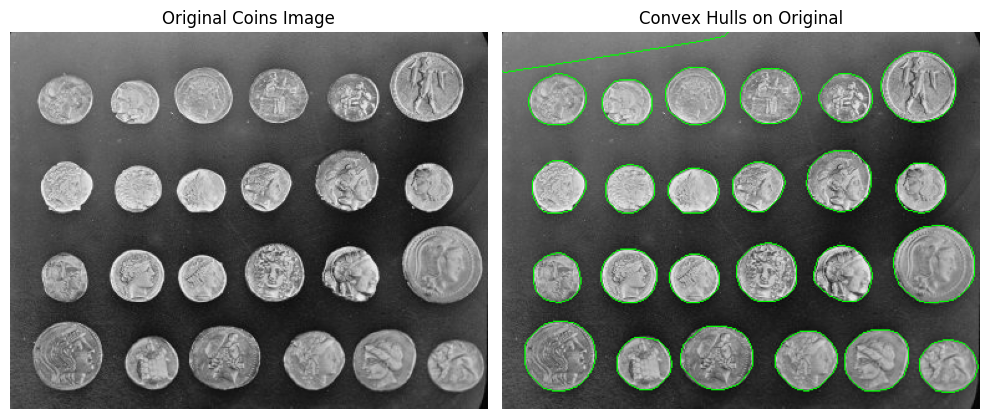

In [41]:
from skimage.util import img_as_ubyte
#maska
hull_edges = np.zeros(coins_uint8.shape, dtype=bool)

for contour in contours:
    object_mask = np.zeros(coins_uint8.shape, dtype=np.uint8)
    cv2.drawContours(object_mask, [contour], -1, 255, thickness=cv2.FILLED)

    hull = convex_hull_image(object_mask > 0)

    hull_edges |= find_boundaries(hull, mode="outer")

#rysowanie
original = img_as_ubyte(coins)
overlay = cv2.cvtColor(original, cv2.COLOR_GRAY2BGR)
overlay[hull_edges] = (0, 255, 0)  

display_image(
    [coins, overlay],
    titles=["Original Coins Image", "Convex Hulls on Original"]
)

In [42]:
for i, contour in enumerate(contours, start=1):
    object_mask = np.zeros(coins_uint8.shape, dtype=np.uint8)
    cv2.drawContours(object_mask, [contour], -1, 255, thickness=cv2.FILLED)

    hull = convex_hull_image(object_mask > 0)

    object_area = np.count_nonzero(object_mask)
    hull_area = np.count_nonzero(hull)

    concavity = (hull_area - object_area) / hull_area if hull_area else 0

    print(
        f"Obiekt {i}: pole={object_area}, "
        f"pole otoczki={hull_area}, miara wklęsłości={concavity:.4f}"
    )

Obiekt 1: pole=1433, pole otoczki=1472, miara wklęsłości=0.0265
Obiekt 2: pole=1351, pole otoczki=1386, miara wklęsłości=0.0253
Obiekt 3: pole=1708, pole otoczki=1747, miara wklęsłości=0.0223
Obiekt 4: pole=1920, pole otoczki=1957, miara wklęsłości=0.0189
Obiekt 5: pole=2143, pole otoczki=2244, miara wklęsłości=0.0450
Obiekt 6: pole=2395, pole otoczki=2442, miara wklęsłości=0.0192
Obiekt 7: pole=1144, pole otoczki=1172, miara wklęsłości=0.0239
Obiekt 8: pole=1093, pole otoczki=1140, miara wklęsłości=0.0412
Obiekt 9: pole=1464, pole otoczki=1494, miara wklęsłości=0.0201
Obiekt 10: pole=1498, pole otoczki=1550, miara wklęsłości=0.0335
Obiekt 11: pole=1697, pole otoczki=1732, miara wklęsłości=0.0202
Obiekt 12: pole=3042, pole otoczki=3120, miara wklęsłości=0.0250
Obiekt 13: pole=1087, pole otoczki=1116, miara wklęsłości=0.0260
Obiekt 14: pole=1110, pole otoczki=1141, miara wklęsłości=0.0272
Obiekt 15: pole=1169, pole otoczki=1204, miara wklęsłości=0.0291
Obiekt 16: pole=1197, pole otoczki

### Dostajemy 25 obiektow poniewaz jeden z nich, zdaje sie ze 25 to niechciany element uchwycony w lewym gornym rogu

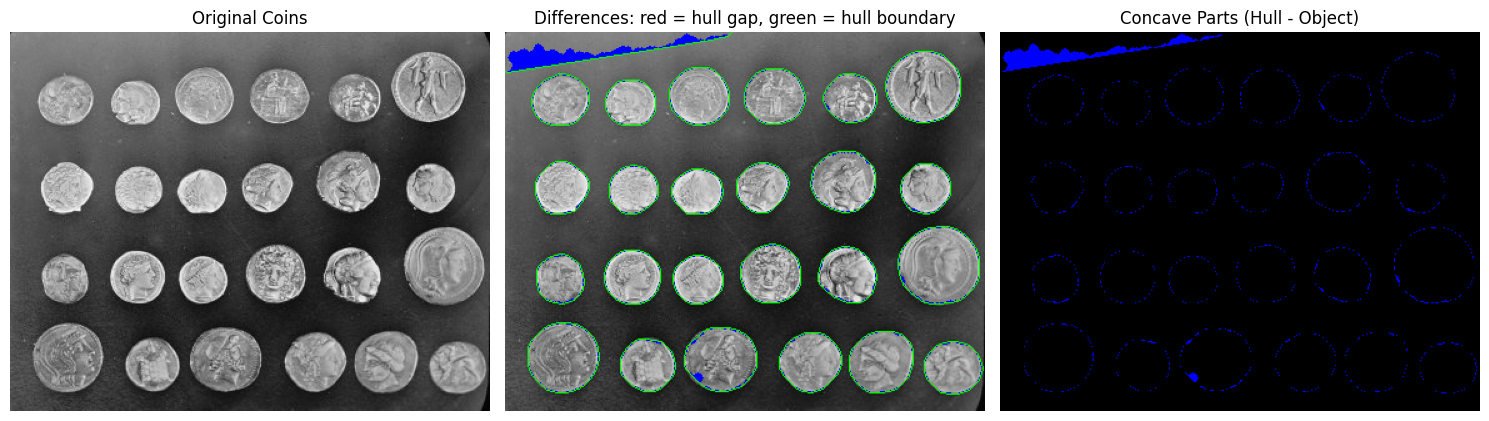

In [43]:
original = img_as_ubyte(coins)
overlay = cv2.cvtColor(original, cv2.COLOR_GRAY2BGR)
difference_image = np.zeros_like(overlay)

for contour in contours:
    object_mask = np.zeros(coins_uint8.shape, dtype=np.uint8)
    cv2.drawContours(object_mask, [contour], -1, 255, thickness=cv2.FILLED)

    hull = convex_hull_image(object_mask > 0)

    difference = hull & (object_mask == 0)
    overlay[difference] = (0, 0, 255)       
    difference_image[difference] = (0, 0, 255)


    hull_boundary = find_boundaries(hull, mode="outer")
    overlay[hull_boundary] = (0, 255, 0)     

display_image(
    [original, overlay, difference_image],
    titles=[
        "Original Coins",
        "Differences: red = hull gap, green = hull boundary",
        "Concave Parts (Hull - Object)"
    ]
)